# Marketing Science Empirical Analysis: Final Training Step (No Early Stopping)

Evaluation of `KEV-0.8B`, `KEV-4B`, and `KEV-9B` at the final epoch-3 training step (`last`, zero validation selection and zero early stopping) across two universal metrics: **Population Slope MSE ($\beta\text{ MSE}$)** and **Choice-Distribution KL Divergence ($\text{Choice KL}$)**. Both `Food labels` (disjoint attributes: no price or sustainability) and `Flights` (shared attributes: price and sustainable aviation fuel) are strictly held-out zero-shot evaluations under this protocol. `Vaccines` (Kreps et al., 2020) is excluded because final-step checkpoints (`last.pt`) were not saved to disk.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from cycler import cycler

PALETTE_NAME = "lancet"
PALETTES = {
    "nature": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
    "lancet": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
}
NEUTRALS = {
    "text": "#2B2B2B",
    "muted": "#52514E",
    "ref_line": "#6E6A64",
    "baseline": "#9A9893",
    "grid": "#D4D2CC",
    "legend_edge": "#E0DED8",
}
PAL = PALETTES[PALETTE_NAME]
plt.rcParams["axes.prop_cycle"] = cycler(color=PAL)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", None)

CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
PAPER_DIR = BETA_TRAINING_DIR / "ms_paper_beta_loss"
PAPER_RUNS_ROOT = PAPER_DIR / "runs-rorqual"
REGIME_RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
LOCAL_PAPER_RUNS_ROOT = PAPER_DIR / "runs"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR), str(PAPER_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from beta_train import runs as run_store
from paper_beta import extract_step0_from_run_dir, load_paper_run

MODEL_SLUGS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_DISPLAY = {
    "kev-0.8b": "KEV-0.8B",
    "kev-4b": "KEV-4B",
    "kev-9b": "KEV-9B",
}
VALIDATORS = ("kriner2026", "grummon2025")

REGIME_LABELS = {
    "row1_base_untrained": "Row 1: Untrained",
    "row2_wu_table_anchored": "Row 2: Electricity (OLS slopes, KL = 0.005)",
    "row2_ablation_wu_table_no_kl": "Row 2: Electricity (OLS slopes, no anchor)",
    "row2b_wu_ce_oracle": "Row 2b: Electricity (microdata)",
    "row3_berke_ce_only": "Row 3: Drones (microdata)",
    "row4_hybrid_berke_ce_wu_table_anchored": "Row 4: Drones (microdata) + Electricity (OLS slopes, KL = 0.005)",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Row 4: Drones (microdata) + Electricity (OLS slopes, no anchor)",
    "row5_full_berke_wu_ce_oracle": "Row 5: Drones + Electricity (microdata)",
}
ALL_SLUGS = tuple(REGIME_LABELS.keys())
TRAINED_SLUGS = tuple(k for k in ALL_SLUGS if k != "row1_base_untrained")


def print_caption(label: str, title: str) -> None:
    print(label)
    print(title)


def print_note(note: str) -> None:
    print(f"Note. {note}")


def find_run_dir(model_slug: str, slug: str) -> Path:
    found = []
    for root in REGIME_RUN_ROOTS:
        candidate = root / model_slug / slug
        if (candidate / "run.json").exists():
            found.append(candidate)
    if len(found) > 1:
        raise ValueError(f"{model_slug}/{slug} exists in more than one run root: {found}")
    if len(found) == 1:
        return found[0]
    raise FileNotFoundError(f"Missing run directory for {model_slug}/{slug} in {REGIME_RUN_ROOTS}")


print(f"PAPER_RUNS_ROOT (alpha sweeps): {PAPER_RUNS_ROOT}")
print(f"REGIME_RUN_ROOTS: {[str(r) for r in REGIME_RUN_ROOTS]}")

PAPER_RUNS_ROOT (alpha sweeps): /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual
REGIME_RUN_ROOTS: ['/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual', '/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-nibi']


---
## Datasets: Shorthand Reference (Table 0a)

In [ ]:
from beta_ols import berke2023 as ds_berke
from beta_ols import grummon2025 as ds_grummon
from beta_ols import kriner2026 as ds_kriner
from beta_ols import wu2025 as ds_wu

DATASET_SPECS = (
    (
        "Electricity",
        "Wu (2025)",
        "Energy Research & Social Science",
        "Training (OLS slopes or microdata)",
        "Monthly bill ($105 to $125), renewable share, local renewables",
        "None",
        ds_wu,
        "CaseID",
        True,
    ),
    (
        "Drones",
        "Berke et al. (2023)",
        "Transportation Research Part C",
        "Training (microdata)",
        "Delivery fee ($0 to $10); no sustainability",
        "Wait time, drone privacy",
        ds_berke,
        "ResponseId",
        False,
    ),
    (
        "Food labels",
        "Grummon et al. (2025)",
        "JAMA Network Open",
        "Disjoint-attribute test (final step)",
        "None",
        "Front-of-package warning labels (6 arms)",
        ds_grummon,
        "participantid",
        True,
    ),
    (
        "Flights",
        "Goldfarb et al. (2026)",
        "Journal of Cleaner Production",
        "Shared-attribute test (final step)",
        "Ticket price ($250 to $325), sustainable aviation fuel",
        "Airline, baggage, legroom, seat",
        ds_kriner,
        "respondent",
        True,
    ),
)

dataset_rows = []
for shorthand, citation, journal, role, shared_attr, other_attr, mod, resp_col, uses_slopes in DATASET_SPECS:
    choice_df = mod.load_choice_df()
    n_resp = int(choice_df[resp_col].nunique())
    n_choices = int(len(choice_df))
    slopes_str = str(len(mod.TARGET_COLUMNS)) if uses_slopes else "n/a"
    dataset_rows.append(
        {
            "Dataset": shorthand,
            "Citation": citation,
            "Journal": journal,
            "Role": role,
            "Shared attributes (price, sustainability)": shared_attr,
            "Other study attributes": other_attr,
            "Respondents": f"{n_resp:,}",
            "Choices": f"{n_choices:,}",
            "OLS slopes": slopes_str,
        }
    ) 

datasets_summary_df = pd.DataFrame(dataset_rows).set_index("Dataset")
print_caption("Table 0a", "Summary of Training and Zero-Shot Test Datasets (Final-Step Evaluation)")
display(datasets_summary_df)
print_note(
    "Both Food labels (Grummon et al., 2025) and Flights (Goldfarb et al., 2026) are evaluated strictly at the final epoch-3 training step with zero early stopping or checkpoint selection. "
    "Vaccines (Kreps et al., 2020) is omitted here because final-step checkpoints (last.pt) were not saved to disk."
)

Table 0a
Summary of Training and Zero-Shot Test Datasets (Final-Step Evaluation)


,Citation,Journal,Role,"Shared attributes (price, sustainability)",Other study attributes,Respondents,Choices,OLS slopes
Dataset,,,,,,,,
Electricity,Wu (2025),Energy Research & Social Science,Training (OLS slopes or microdata),"Monthly bill ($105 to $125), renewable share, local renewables",None,"1,861","18,591",8
Drones,Berke et al. (2023),Transportation Research Part C,Training (microdata),Delivery fee ($0 to $10); no sustainability,"Wait time, drone privacy","3,625","36,297",n/a
Food labels,Grummon et al. (2025),JAMA Network Open,Disjoint-attribute test (final step),None,Front-of-package warning labels (6 arms),"5,633","33,798",5
Flights,Goldfarb et al. (2026),Journal of Cleaner Production,Shared-attribute test (final step),"Ticket price ($250 to $325), sustainable aviation fuel","Airline, baggage, legroom, seat","1,000","5,000",12


Note. Both Food labels (Grummon et al., 2025) and Flights (Goldfarb et al., 2026) are evaluated strictly at the final epoch-3 training step with zero early stopping or checkpoint selection. Vaccines (Kreps et al., 2020) is omitted here because final-step checkpoints (last.pt) were not saved to disk.


---
## Step 0: Final-Step Run Inventory

In [3]:
def collect_model_regimes_last(model_slug: str) -> pd.DataFrame:
    first_dir = find_run_dir(model_slug, TRAINED_SLUGS[0])
    step0 = extract_step0_from_run_dir(first_dir, VALIDATORS)

    rows = [
        {
            "slug": "row1_base_untrained",
            "regime": REGIME_LABELS["row1_base_untrained"],
            "last_step": 0,
            "progress": "step 0",
            "kriner_mse": float(step0["metrics"]["kriner2026/beta_mse"]),
            "kriner_kl": float(step0["metrics"]["kriner2026/kl_loss"]),
            "grummon_mse": float(step0["metrics"]["grummon2025/beta_mse"]),
            "grummon_kl": float(step0["metrics"]["grummon2025/kl_loss"]),
        }
    ]

    for slug in TRAINED_SLUGS:
        run_dir = find_run_dir(model_slug, slug)
        run_info = run_store.read_run_json(run_dir)
        raw_status = run_info["status"]
        if raw_status != run_store.STATUS_FINISHED:
            raise RuntimeError(f"Expected finished run for {model_slug}/{slug}, got status={raw_status!r}")

        result = load_paper_run(run_dir)
        steps_done = len(result.step_df)
        last_step = int(result.val_history_df.index[-1])
        if last_step != steps_done:
            raise ValueError(f"{model_slug}/{slug}: final val_history step {last_step} != final training step {steps_done}")

        last_row = result.val_history_df.loc[last_step]
        required_cols = (
            "kriner2026/beta_mse",
            "kriner2026/kl_loss",
            "grummon2025/beta_mse",
            "grummon2025/kl_loss",
        )
        for col in required_cols:
            if col not in last_row.index or pd.isna(last_row[col]):
                raise ValueError(f"{model_slug}/{slug} at step {last_step}: missing or NaN {col!r}")

        betas_csv = run_dir / "betas" / f"step_{last_step:06d}.csv"
        if not betas_csv.exists():
            raise FileNotFoundError(f"Missing final-step betas CSV: {betas_csv}")

        rows.append(
            {
                "slug": slug,
                "regime": REGIME_LABELS[slug],
                "last_step": last_step,
                "progress": f"{raw_status} (@last={last_step})",
                "kriner_mse": float(last_row["kriner2026/beta_mse"]),
                "kriner_kl": float(last_row["kriner2026/kl_loss"]),
                "grummon_mse": float(last_row["grummon2025/beta_mse"]),
                "grummon_kl": float(last_row["grummon2025/kl_loss"]),
            }
        )

    return pd.DataFrame(rows).set_index("slug")


regimes_by_model: dict[str, pd.DataFrame] = {}
for model_slug in MODEL_SLUGS:
    regimes_by_model[model_slug] = collect_model_regimes_last(model_slug)

status_grid = pd.DataFrame(
    {MODEL_DISPLAY[m]: regimes_by_model[m].loc[list(ALL_SLUGS), "progress"].values for m in MODEL_SLUGS},
    index=[REGIME_LABELS[s] for s in ALL_SLUGS],
)
status_grid.index.name = "Regime"
display(status_grid)

,KEV-0.8B,KEV-4B,KEV-9B
Regime,,,
Row 1: Untrained,step 0,step 0,step 0
"Row 2: Electricity (OLS slopes, KL = 0.005)",finished (@last=1395),finished (@last=1395),finished (@last=1395)
"Row 2: Electricity (OLS slopes, no anchor)",finished (@last=1395),finished (@last=1395),finished (@last=1395)
Row 2b: Electricity (microdata),finished (@last=1395),finished (@last=1395),finished (@last=1395)
Row 3: Drones (microdata),finished (@last=2730),finished (@last=2730),finished (@last=2730)
"Row 4: Drones (microdata) + Electricity (OLS slopes, KL = 0.005)",finished (@last=4125),finished (@last=4125),finished (@last=4125)
"Row 4: Drones (microdata) + Electricity (OLS slopes, no anchor)",finished (@last=4125),finished (@last=4125),finished (@last=4125)
Row 5: Drones + Electricity (microdata),finished (@last=4125),finished (@last=4125),finished (@last=4125)


---
## Shared Table and Figure Helpers

In [4]:
from matplotlib.ticker import FuncFormatter, NullFormatter

BASE_SLUG = "row1_base_untrained"
MSE_SCALE = 1000.0
STORY_COLUMNS = (
    ("grummon", "Food labels"),
    ("kriner", "Flights"),
)
STORY_LABELS = {
    "row1_base_untrained": "Untrained",
    "row2_wu_table_anchored": "Electricity (OLS slopes)",
    "row2_ablation_wu_table_no_kl": "Electricity (OLS slopes, no anchor)",
    "row2b_wu_ce_oracle": "Electricity (microdata)",
    "row3_berke_ce_only": "Drones (microdata)",
    "row4_hybrid_berke_ce_wu_table_anchored": "Drones (microdata) + Electricity (OLS slopes)",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Drones (microdata) + Electricity (OLS slopes, no anchor)",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity (microdata)",
}
STORY_COLORS = {
    "row2_wu_table_anchored": PAL[1],
    "row2_ablation_wu_table_no_kl": PAL[1],
    "row2b_wu_ce_oracle": PAL[2],
    "row3_berke_ce_only": PAL[4],
    "row4_hybrid_berke_ce_wu_table_anchored": PAL[3],
    "row4_hybrid_berke_ce_wu_table_no_kl": PAL[3],
    "row5_full_berke_wu_ce_oracle": PAL[0],
}
HOLLOW_SLUGS = {"row2_ablation_wu_table_no_kl", "row4_hybrid_berke_ce_wu_table_no_kl"}
ROLES_NOTE = (
    "Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). "
    "Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); "
    "Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). "
    "Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved."
)
TABLE_LETTERS = "abcdefgh"


def build_metric_table(models: tuple[str, ...], slugs: tuple[str, ...], metric_suffix: str, columns: tuple) -> pd.DataFrame:
    frames = []
    for model_slug in models:
        sub = regimes_by_model[model_slug].loc[list(slugs)]
        frame_columns = {}
        for ds_key, ds_label in columns:
            frame_columns[ds_label] = sub[f"{ds_key}_{metric_suffix}"].astype(float)
        frame = pd.DataFrame(frame_columns)
        frame.index = pd.MultiIndex.from_tuples(
            [(MODEL_DISPLAY[model_slug], s) for s in sub.index],
            names=["Model", "Trained on"],
        )
        frames.append(frame)
    return pd.concat(frames)


def format_mse_cell(value: float, base_value: float, slug: str) -> str:
    scaled = value * MSE_SCALE
    if slug == BASE_SLUG:
        return f"{scaled:.2f}"
    change_pct = 100.0 * (value - base_value) / base_value
    return f"{scaled:.2f} ({change_pct:+.0f}%)"


def format_pct(value: float) -> str:
    return f"{value:+.0f}%"


def best_cell_css(values: pd.DataFrame) -> pd.DataFrame:
    css = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name in values.index.get_level_values("Model").unique():
        model_block = values.xs(model_name, level="Model", drop_level=False)
        trained_block = model_block.drop(index=BASE_SLUG, level="Trained on")
        for col in values.columns:
            if trained_block[col].notna().sum() < 2:
                continue
            best_index = trained_block[col].idxmin()
            best_value = float(trained_block.loc[best_index, col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            if best_value < base_value:
                css.loc[best_index, col] = "font-weight: bold"
    return css


def relabel_rows(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out.index = pd.MultiIndex.from_tuples(
        [(model_name, STORY_LABELS[slug]) for model_name, slug in out.index],
        names=out.index.names,
    )
    return out


def build_mse_styler(models: tuple[str, ...], slugs: tuple[str, ...], columns: tuple):
    values = build_metric_table(models, slugs, "mse", columns)
    text = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name, slug in values.index:
        for col in values.columns:
            value = float(values.loc[(model_name, slug), col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            text.loc[(model_name, slug), col] = format_mse_cell(value, base_value, slug)

    css = relabel_rows(best_cell_css(values))
    return relabel_rows(text).style.apply(lambda _f: css, axis=None)


def plot_dot_panels(models: tuple[str, ...], slugs: tuple[str, ...], datasets: tuple, y_offsets: dict, x_ticks: tuple, reference_slug: str) -> None:
    if reference_slug not in slugs:
        raise ValueError(f"reference_slug {reference_slug!r} not in slugs {slugs}")
    if y_offsets[reference_slug] != y_offsets[BASE_SLUG]:
        raise ValueError(f"reference {reference_slug!r} offset != untrained offset")
    fig, axes = plt.subplots(
        1,
        len(models),
        figsize=(3.6 * len(models) + 4.4, 0.95 * len(datasets) + 1.4),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    axes = axes[0]
    y_positions = np.arange(len(datasets))

    for ax, model_slug in zip(axes, models):
        sub = regimes_by_model[model_slug].loc[list(slugs)]
        if len(datasets) == 2 and datasets[-1][0] == "kriner":
            ax.axhline(0.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
        for y, (ds_key, _) in zip(y_positions, datasets):
            base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"]) * MSE_SCALE
            end_value = float(sub.loc[reference_slug, f"{ds_key}_mse"]) * MSE_SCALE
            bar_y = y + y_offsets[BASE_SLUG]
            ax.plot([end_value, base_value], [bar_y, bar_y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)

        for slug in slugs:
            values = [float(sub.loc[slug, f"{ds_key}_mse"]) * MSE_SCALE for ds_key, _ in datasets]
            y_shifted = y_positions + y_offsets[slug]
            if slug == BASE_SLUG:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            elif slug in HOLLOW_SLUGS:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=STORY_COLORS[slug], linewidths=1.6, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(values, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])

        ax.set_xscale("log")
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE (×10³)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(y_positions)
    axes[0].set_yticklabels([label for _, label in datasets])
    axes[0].set_ylim(-0.5, len(datasets) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()

---
## Overview: The Story at a Glance (Table 0b, Figure 0)

Table 0b
Overview of Training Regimes at Final Training Step (No Early Stopping)


Data used                                             KEV-0.8B              KEV-4B              KEV-9B            
                                               Step Electricity (microdata) Electricity (OLS slopes) Drones (microdata)  Flights Food labels Flights Food labels Flights Food labels
Trained on                                                                                                                                                                          
Electricity (OLS slopes)                          2                                                ✓                        -58%        -24%    -26%        -71%    -53%        -58%
Electricity (microdata)                        1, 2                       ✓                                                 -43%        -36%    -46%        -80%    -53%        -11%
Drones (microdata)                             1, 3                                                                   ✓     -40%        -33%    -54%        -69%    -17%        -85%
Drones (microdata) + Electricity (OLS slopes)     3                                                ✓                  ✓     -69%        -25%    -86%        -75%    -78%        -72%
Drones + Electricity (microdata)               1, 3                       ✓                                           ✓     -65%        -43%    -72%        -90%    -69%        -46%

Note. Values are percentage changes in population β MSE versus the untrained model; negative is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.
Figure 0
Final-Step Change in β MSE: Flights (Shared Attributes) Versus Food Labels (Disjoint Attributes)


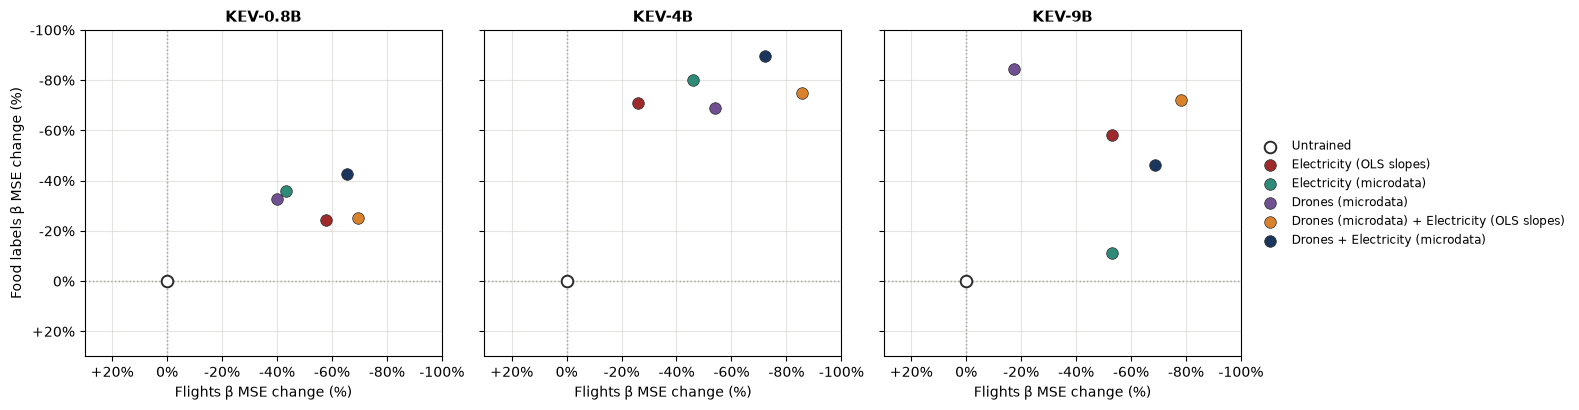

Note. Each point is one training regime evaluated at the final epoch-3 step (no early stopping). x-axis: Flights (shared price and sustainability attributes); y-axis: Food labels (disjoint attributes). Both axes show percentage change in population β MSE versus the untrained model (open circle at origin) and are reversed so up and right are better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


In [5]:
OVERVIEW_MODELS = MODEL_SLUGS
OVERVIEW_SLUGS = (
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
OVERVIEW_STEP = {
    "row2_wu_table_anchored": "2",
    "row2b_wu_ce_oracle": "1, 2",
    "row3_berke_ce_only": "1, 3",
    "row4_hybrid_berke_ce_wu_table_anchored": "3",
    "row5_full_berke_wu_ce_oracle": "1, 3",
}
OVERVIEW_DATA_USED = {
    "row2_wu_table_anchored": ("", "✓", ""),
    "row2b_wu_ce_oracle": ("✓", "", ""),
    "row3_berke_ce_only": ("", "", "✓"),
    "row4_hybrid_berke_ce_wu_table_anchored": ("", "✓", "✓"),
    "row5_full_berke_wu_ce_oracle": ("✓", "", "✓"),
}


def pct_change_vs_base(model_slug: str, slug: str, ds_key: str) -> float:
    sub = regimes_by_model[model_slug]
    base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"])
    value = float(sub.loc[slug, f"{ds_key}_mse"])
    return 100.0 * (value - base_value) / base_value


overview_rows = []
for slug in OVERVIEW_SLUGS:
    elec_micro, elec_slopes, drones_micro = OVERVIEW_DATA_USED[slug]
    row = {
        ("", "Trained on"): STORY_LABELS[slug],
        ("", "Step"): OVERVIEW_STEP[slug],
        ("Data used", "Electricity (microdata)"): elec_micro,
        ("Data used", "Electricity (OLS slopes)"): elec_slopes,
        ("Data used", "Drones (microdata)"): drones_micro,
    }
    for model_slug in OVERVIEW_MODELS:
        row[(MODEL_DISPLAY[model_slug], "Flights")] = format_pct(pct_change_vs_base(model_slug, slug, "kriner"))
        row[(MODEL_DISPLAY[model_slug], "Food labels")] = format_pct(pct_change_vs_base(model_slug, slug, "grummon"))
    overview_rows.append(row)

overview_df = pd.DataFrame(overview_rows)
overview_df.columns = pd.MultiIndex.from_tuples(overview_df.columns)
overview_df = overview_df.set_index([("", "Trained on")])
overview_df.index.name = "Trained on"
print_caption("Table 0b", "Overview of Training Regimes at Final Training Step (No Early Stopping)")
display(overview_df)
print_note(
    "Values are percentage changes in population β MSE versus the untrained model; negative is better. "
    f"{ROLES_NOTE}"
)

OVERVIEW_AXIS_LIMITS = (30.0, -100.0)
signed_pct_formatter = FuncFormatter(lambda v, _: "0%" if v == 0 else f"{v:+.0f}%")

print_caption("Figure 0", "Final-Step Change in β MSE: Flights (Shared Attributes) Versus Food Labels (Disjoint Attributes)")

fig, axes = plt.subplots(1, len(OVERVIEW_MODELS), figsize=(3.9 * len(OVERVIEW_MODELS) + 4.2, 4.2), sharex=True, sharey=True)
for ax, model_slug in zip(axes, OVERVIEW_MODELS):
    ax.axhline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.scatter([0.0], [0.0], s=70, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[BASE_SLUG])
    for slug in OVERVIEW_SLUGS:
        x_value = pct_change_vs_base(model_slug, slug, "kriner")
        y_value = pct_change_vs_base(model_slug, slug, "grummon")
        ax.scatter([x_value], [y_value], s=70, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Flights β MSE change (%)")
    ax.xaxis.set_major_formatter(signed_pct_formatter)
    ax.yaxis.set_major_formatter(signed_pct_formatter)
    ax.grid(color=NEUTRALS["grid"], alpha=0.6)
    ax.set_xlim(OVERVIEW_AXIS_LIMITS)
    ax.set_ylim(OVERVIEW_AXIS_LIMITS)

axes[0].set_ylabel("Food labels β MSE change (%)")
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Each point is one training regime evaluated at the final epoch-3 step (no early stopping). "
    "x-axis: Flights (shared price and sustainability attributes); y-axis: Food labels (disjoint attributes). "
    "Both axes show percentage change in population β MSE versus the untrained model (open circle at origin) and are reversed so up and right are better. "
    f"{ROLES_NOTE}"
)

---
## Step 1: Microdata Fine-Tuning Transfers to Unseen Domains

In [6]:
STEP1_MODELS = MODEL_SLUGS
STEP1_SLUGS = (
    "row1_base_untrained",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row5_full_berke_wu_ce_oracle",
)

print_caption("Table 1", "Final-Step Population β MSE After Microdata Fine-Tuning")
display(build_mse_styler(STEP1_MODELS, STEP1_SLUGS, STORY_COLUMNS))
print_note(
    "Values are population β MSE ×10³ at the final step, with percentage change versus Untrained in parentheses; lower is better. "
    f"{ROLES_NOTE}"
)

Table 1
Final-Step Population β MSE After Microdata Fine-Tuning


Note. Values are population β MSE ×10³ at the final step, with percentage change versus Untrained in parentheses; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


Figure 1
Final-Step Microdata Fine-Tuning Across Benchmarks


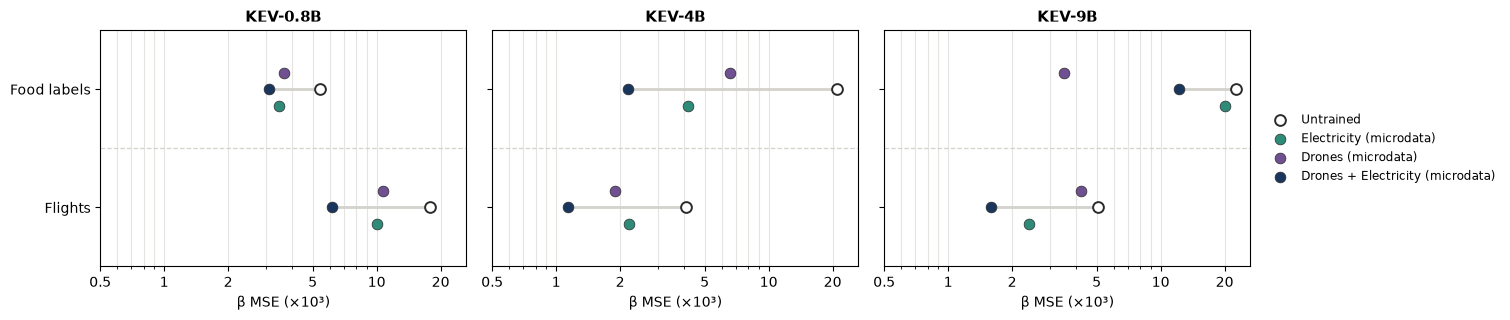

Note. Open circles are Untrained; filled circles are final-step fine-tuned models. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity (microdata). Dashed line separates disjoint-attribute (above) from shared-attribute (below). Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


In [7]:
print_caption("Figure 1", "Final-Step Microdata Fine-Tuning Across Benchmarks")
plot_dot_panels(
    models=STEP1_MODELS,
    slugs=STEP1_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2b_wu_ce_oracle": 0.14,
        "row3_berke_ce_only": -0.14,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.5, 1, 2, 5, 10, 20),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note(
    "Open circles are Untrained; filled circles are final-step fine-tuned models. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins Untrained to Drones + Electricity (microdata). Dashed line separates disjoint-attribute (above) from shared-attribute (below). "
    f"{ROLES_NOTE}"
)

---
## Step 2: Published OLS Slopes Alone Versus Matched Microdata

In [8]:
STEP2_MODELS = MODEL_SLUGS
STEP2_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
)

print_caption("Table 2", "Final-Step Electricity (OLS Slopes) Versus Electricity (Microdata)")
display(build_mse_styler(STEP2_MODELS, STEP2_SLUGS, STORY_COLUMNS))
print_note(
    "Electricity (OLS slopes) trains on 8 published-specification OLS slopes from Wu (2025) with KL anchor α = 0.005 (all 18,591 choices withheld). "
    f"{ROLES_NOTE}"
)

Table 2
Final-Step Electricity (OLS Slopes) Versus Electricity (Microdata)


Note. Electricity (OLS slopes) trains on 8 published-specification OLS slopes from Wu (2025) with KL anchor α = 0.005 (all 18,591 choices withheld). Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


Figure 2
Final-Step Electricity (OLS Slopes) Versus Electricity (Microdata)


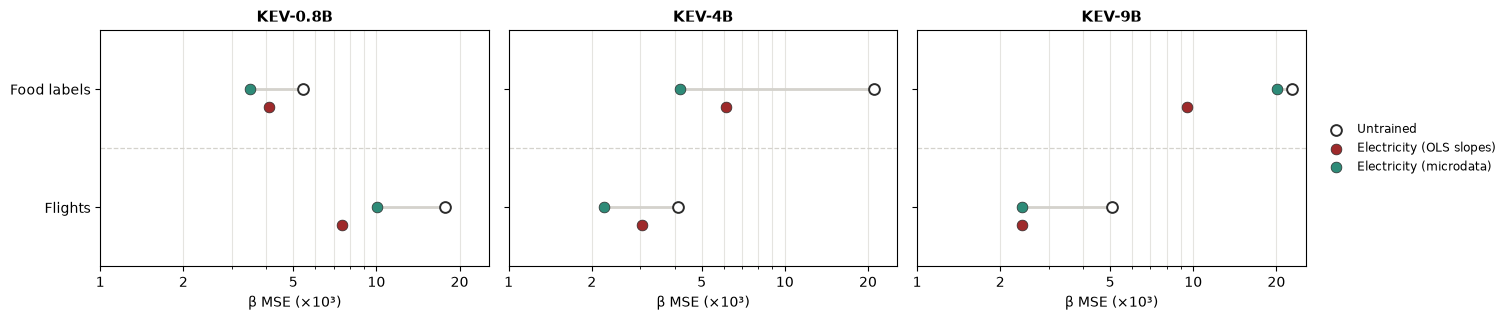

Note. Open circles are Untrained; filled circles are final-step fine-tuned models. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Electricity (microdata). Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


In [9]:
print_caption("Figure 2", "Final-Step Electricity (OLS Slopes) Versus Electricity (Microdata)")
plot_dot_panels(
    models=STEP2_MODELS,
    slugs=STEP2_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2_wu_table_anchored": 0.15,
        "row2b_wu_ce_oracle": 0.0,
    },
    x_ticks=(1, 2, 5, 10, 20),
    reference_slug="row2b_wu_ce_oracle",
)
print_note(
    "Open circles are Untrained; filled circles are final-step fine-tuned models. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins Untrained to Electricity (microdata). "
    f"{ROLES_NOTE}"
)

---
## Step 3: Combining In-House Microdata With External OLS Slopes

In [10]:
STEP3_MODELS = MODEL_SLUGS
STEP3_SLUGS = (
    "row1_base_untrained",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)

print_caption("Table 3", "Final-Step Hybrid Versus Drones Microdata and Pooled Microdata")
display(build_mse_styler(STEP3_MODELS, STEP3_SLUGS, STORY_COLUMNS))
print_note(
    "Drones (microdata) + Electricity (OLS slopes) combines 36,297 choices from Berke et al. (2023) with 8 OLS slopes from Wu (2025) and KL anchor α = 0.005. "
    f"{ROLES_NOTE}"
)

Table 3
Final-Step Hybrid Versus Drones Microdata and Pooled Microdata


Note. Drones (microdata) + Electricity (OLS slopes) combines 36,297 choices from Berke et al. (2023) with 8 OLS slopes from Wu (2025) and KL anchor α = 0.005. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


Figure 3
Final-Step Hybrid Versus Drones Microdata and Pooled Microdata


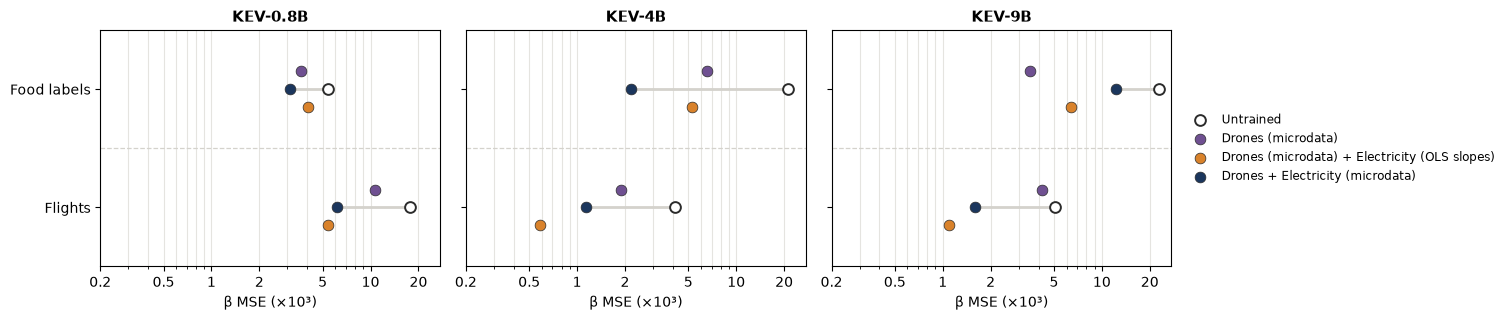

Note. Open circles are Untrained; filled circles are final-step fine-tuned models. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity (microdata). Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


In [11]:
print_caption("Figure 3", "Final-Step Hybrid Versus Drones Microdata and Pooled Microdata")
plot_dot_panels(
    models=STEP3_MODELS,
    slugs=STEP3_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row3_berke_ce_only": -0.15,
        "row4_hybrid_berke_ce_wu_table_anchored": 0.15,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.2, 0.5, 1, 2, 5, 10, 20),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note(
    "Open circles are Untrained; filled circles are final-step fine-tuned models. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins Untrained to Drones + Electricity (microdata). "
    f"{ROLES_NOTE}"
)

---
## Step 4: Where the OLS Slopes Help: Final-Step `Flights` Slopes by Attribute

Figure 4
Final-Step Flights Slope Errors by Attribute


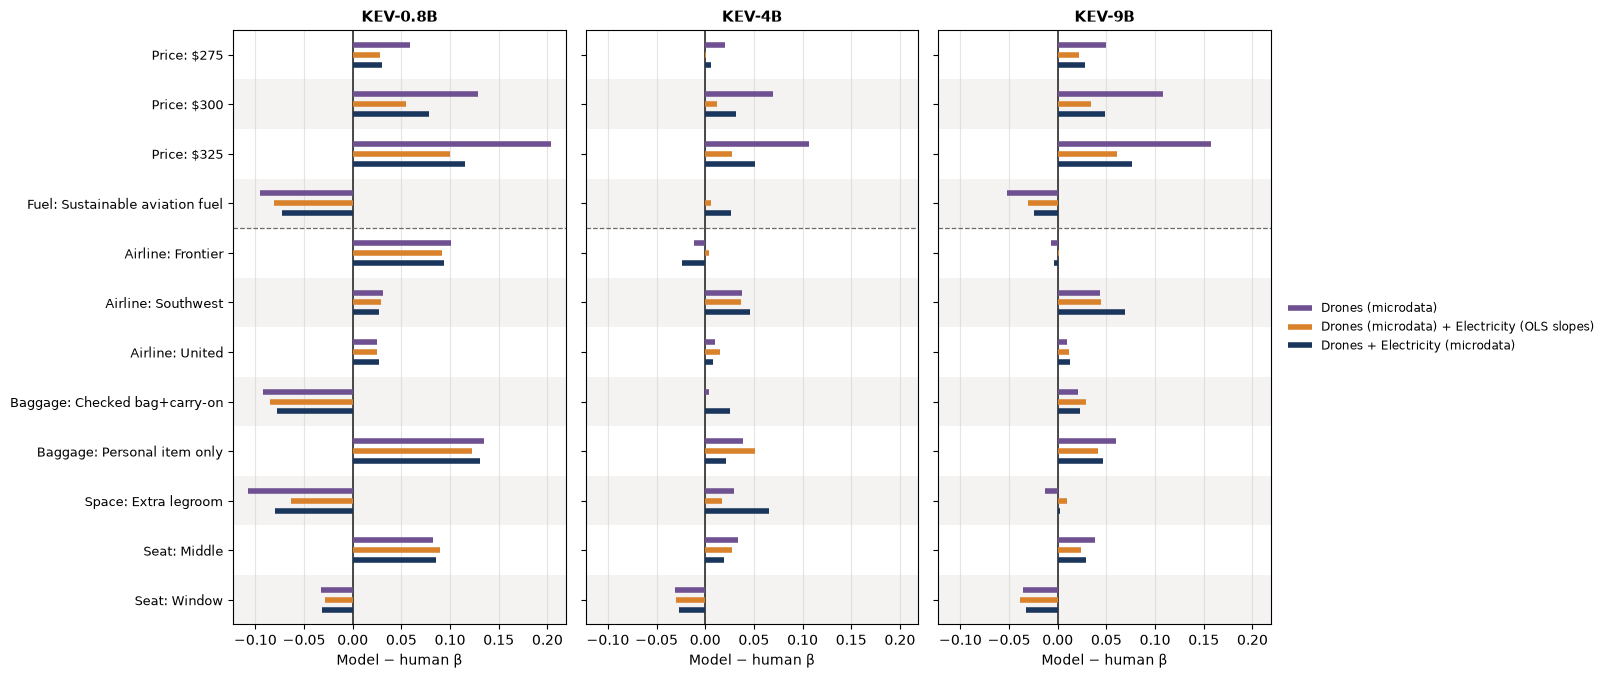

Note. Bars show model minus human population β at the final epoch-3 step for each Flights (Goldfarb et al., 2026) attribute level; 0 matches humans. Price and sustainable aviation fuel (shared with Electricity) appear above the dashed divider. Numbers are in Table A6.


In [12]:
STEP4_MODELS = MODEL_SLUGS
STEP4_SLUGS = (
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
STEP4_Y_OFFSETS = {
    "row3_berke_ce_only": -0.2,
    "row4_hybrid_berke_ce_wu_table_anchored": 0.0,
    "row5_full_berke_wu_ce_oracle": 0.2,
}


def load_kriner_last_betas(model_slug: str, slug: str) -> pd.DataFrame:
    run_dir = find_run_dir(model_slug, slug)
    last_step = int(regimes_by_model[model_slug].loc[slug, "last_step"])
    betas_csv = run_dir / "betas" / f"step_{last_step:06d}.csv"
    if not betas_csv.exists():
        raise FileNotFoundError(f"Missing final-step betas CSV: {betas_csv}")
    df = pd.read_csv(betas_csv)
    sub = df[df["validator"] == "kriner2026"].set_index("term")
    if len(sub) != 12:
        raise ValueError(f"{betas_csv}: expected 12 kriner2026 terms, got {len(sub)}")
    out = sub[["human_pop_beta", "model_pop_beta"]].astype(float)
    if out.isna().any().any():
        raise ValueError(f"{betas_csv}: NaN values in kriner2026 slopes")
    return out


kriner_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
for model_slug in STEP4_MODELS:
    kriner_betas_by_model[model_slug] = {}
    ref_index = None
    for slug in STEP4_SLUGS:
        betas = load_kriner_last_betas(model_slug, slug)
        if ref_index is None:
            ref_index = list(betas.index)
        elif list(betas.index) != ref_index:
            raise ValueError(f"{model_slug}/{slug}: Flights terms mismatch")
        kriner_betas_by_model[model_slug][slug] = betas

all_kriner_terms = list(kriner_betas_by_model[STEP4_MODELS[0]][STEP4_SLUGS[0]].index)
price_terms = [t for t in all_kriner_terms if t.startswith("Price:")]
fuel_terms = [t for t in all_kriner_terms if t.startswith("Fuel:")]
if not price_terms or not fuel_terms:
    raise ValueError(f"Missing price/fuel terms in Flights: {all_kriner_terms}")
transferred_terms = price_terms + fuel_terms
other_terms = [t for t in all_kriner_terms if t not in transferred_terms]
kriner_terms = transferred_terms + other_terms
TRANSFERRED_DIVIDER_Y = len(transferred_terms) - 0.5
y_positions = np.arange(len(kriner_terms))

print_caption("Figure 4", "Final-Step Flights Slope Errors by Attribute")
fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(3.8 * len(STEP4_MODELS) + 4.8, 0.44 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    ax.axvline(0.0, color=NEUTRALS["text"], linewidth=1.2, zorder=2)
    ax.axhline(TRANSFERRED_DIVIDER_Y, color=NEUTRALS["ref_line"], linestyle="--", linewidth=0.9, zorder=2)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)
    for slug in STEP4_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        errors = (betas["model_pop_beta"] - betas["human_pop_beta"]).to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, errors, color=STORY_COLORS[slug], linewidth=4.0, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Model − human β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Bars show model minus human population β at the final epoch-3 step for each Flights (Goldfarb et al., 2026) attribute level; 0 matches humans. "
    "Price and sustainable aviation fuel (shared with Electricity) appear above the dashed divider. Numbers are in Table A6."
)

Figure 5
Final-Step Flights Population β by Attribute: Humans and Models


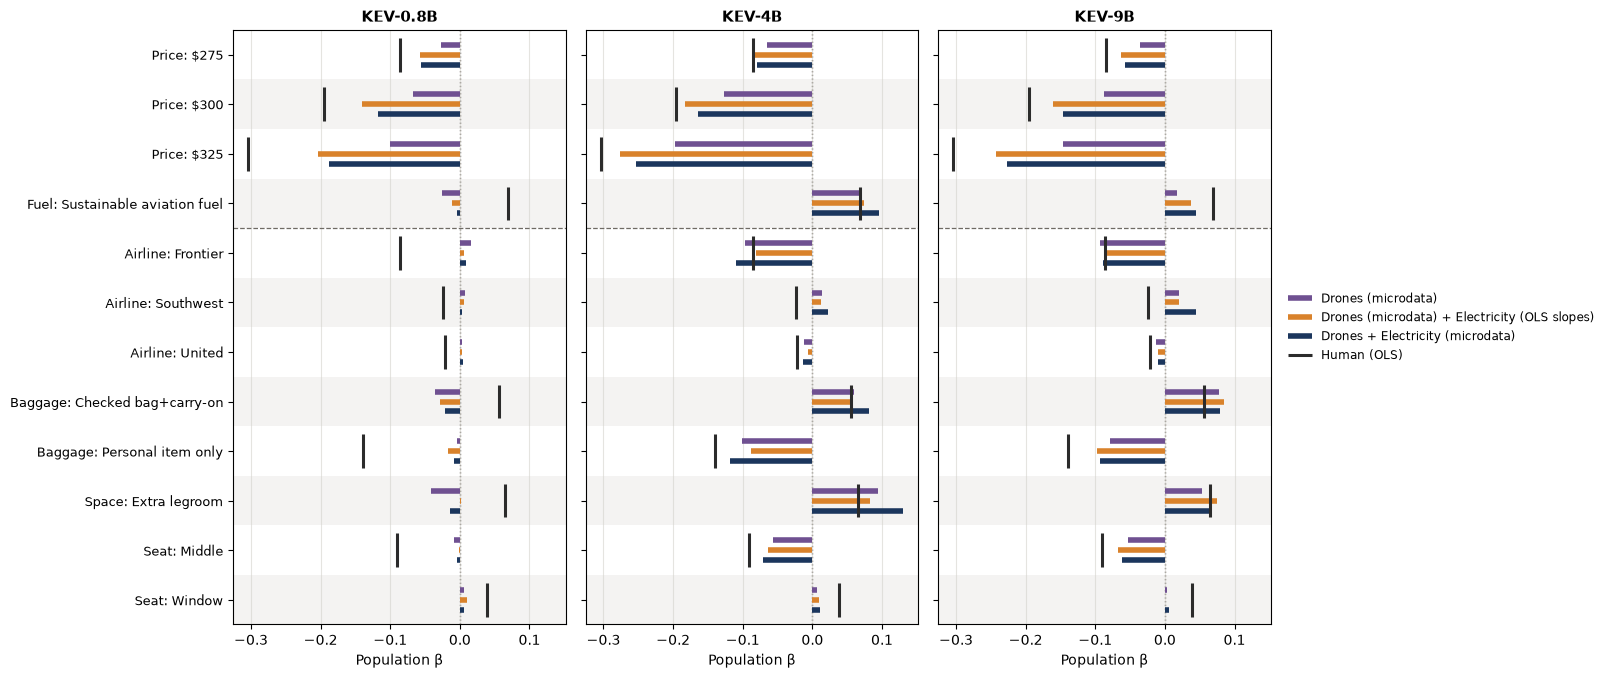

Note. Bars show final-step model population β for each Flights (Goldfarb et al., 2026) attribute level; the vertical black tick marks human OLS. Price and sustainable aviation fuel appear above the dashed divider. Numbers are in Table A6.


In [13]:
HUMAN_TICK_HALF_HEIGHT = 0.34

print_caption("Figure 5", "Final-Step Flights Population β by Attribute: Humans and Models")
fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(3.8 * len(STEP4_MODELS) + 4.8, 0.44 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linewidth=1.0, linestyle=":", zorder=1)
    ax.axhline(TRANSFERRED_DIVIDER_Y, color=NEUTRALS["ref_line"], linestyle="--", linewidth=0.9, zorder=2)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)

    for slug in STEP4_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        model_values = betas["model_pop_beta"].to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, model_values, color=STORY_COLORS[slug], linewidth=4.0, zorder=3, label=STORY_LABELS[slug])

    human_values = kriner_betas_by_model[model_slug][STEP4_SLUGS[0]].loc[kriner_terms, "human_pop_beta"].to_numpy(dtype=float)
    ax.vlines(human_values, y_positions - HUMAN_TICK_HALF_HEIGHT, y_positions + HUMAN_TICK_HALF_HEIGHT, color=NEUTRALS["text"], linewidth=2.2, zorder=4, label="Human (OLS)")

    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Population β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Bars show final-step model population β for each Flights (Goldfarb et al., 2026) attribute level; the vertical black tick marks human OLS. "
    "Price and sustainable aviation fuel appear above the dashed divider. Numbers are in Table A6."
)

---
## Ablation: The KL Anchor at Final Training Step (α = 0.005 vs. α = 0; α Sweep)

In [14]:
ABLATION_MODELS = MODEL_SLUGS
ABLATION_PAIRS = (
    ("a", "Electricity (OLS Slopes) With and Without the KL Anchor (Final Step)", "row2_wu_table_anchored", "row2_ablation_wu_table_no_kl"),
    ("b", "Drones (Microdata) + Electricity (OLS Slopes) With and Without the KL Anchor (Final Step)", "row4_hybrid_berke_ce_wu_table_anchored", "row4_hybrid_berke_ce_wu_table_no_kl"),
)
ABLATION_COLUMNS = STORY_COLUMNS

for letter, title, anchored_slug, no_anchor_slug in ABLATION_PAIRS:
    print_caption(f"Table 4{letter}", title)
    display(build_mse_styler(ABLATION_MODELS, (BASE_SLUG, anchored_slug, no_anchor_slug), ABLATION_COLUMNS))
    print_note(
        "With anchor = KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks with weight α = 0.005; no anchor = α = 0. "
        f"Values are population β MSE ×10³ at the final step; lower is better. {ROLES_NOTE}"
    )

Table 4a
Electricity (OLS Slopes) With and Without the KL Anchor (Final Step)


Note. With anchor = KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³ at the final step; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.
Table 4b
Drones (Microdata) + Electricity (OLS Slopes) With and Without the KL Anchor (Final Step)


Note. With anchor = KL(p₀‖p_θ) on Electricity (Wu, 2025) tasks with weight α = 0.005; no anchor = α = 0. Values are population β MSE ×10³ at the final step; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


Figure 6
Flights Over Training: Electricity (OLS Slopes) With and Without the KL Anchor (Final Step Marked)


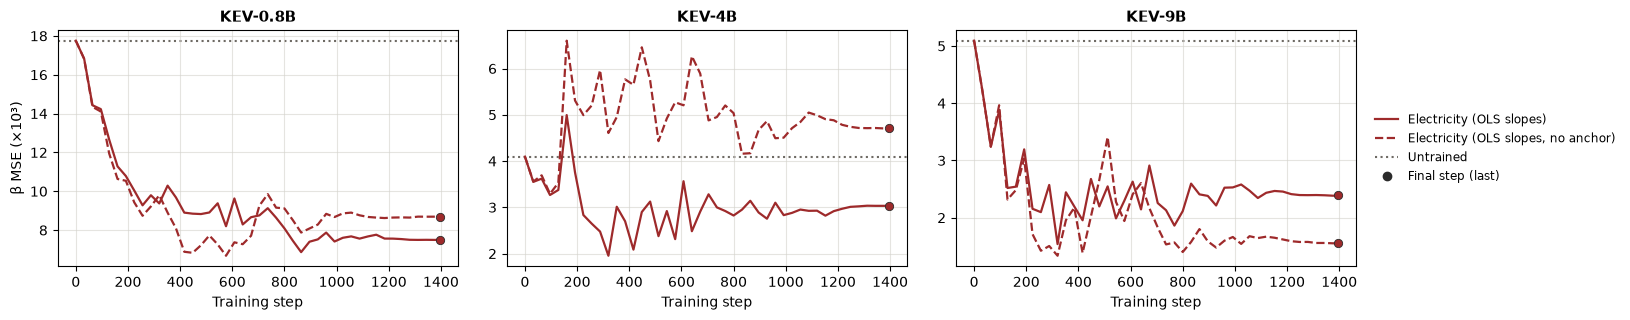

Note. Population β MSE ×10³ on Flights over training, evaluated every 32 steps; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark the final epoch-3 step (no early stopping); the dotted line is Untrained.
Figure 7
Flights Over Training: Hybrid With and Without the KL Anchor (Final Step Marked)


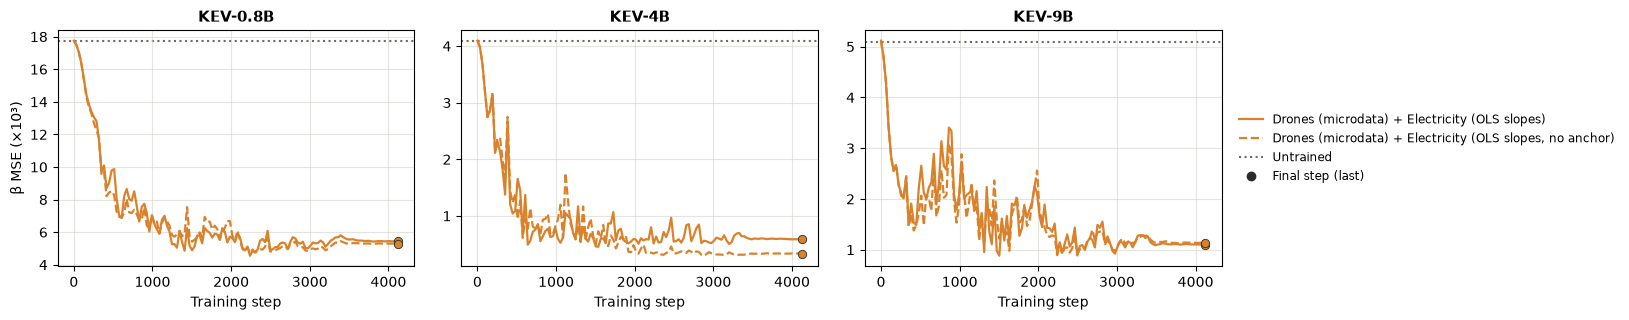

Note. Population β MSE ×10³ on Flights over training, evaluated every 32 steps; lower is better. Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark the final epoch-3 step (no early stopping); the dotted line is Untrained.


In [15]:
def plot_anchor_trajectories_last(anchored_slug: str, no_anchor_slug: str) -> None:
    fig, axes = plt.subplots(1, len(ABLATION_MODELS), figsize=(3.8 * len(ABLATION_MODELS) + 5.0, 3.3), squeeze=False)
    axes = axes[0]
    for ax, model_slug in zip(axes, ABLATION_MODELS):
        base_value = float(regimes_by_model[model_slug].loc[BASE_SLUG, "kriner_mse"]) * MSE_SCALE
        ax.axhline(base_value, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.5, zorder=1)
        for slug, linestyle in ((anchored_slug, "-"), (no_anchor_slug, "--")):
            run_dir = find_run_dir(model_slug, slug)
            result = load_paper_run(run_dir)
            series = result.val_history_df["kriner2026/beta_mse"].dropna() * MSE_SCALE
            ax.plot(series.index, series.values, color=STORY_COLORS[slug], linestyle=linestyle, linewidth=1.6, zorder=2)
            last_step = int(series.index[-1])
            ax.scatter([last_step], [float(series.loc[last_step])], s=36, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.6, zorder=3)
        ax.grid(color=NEUTRALS["grid"], alpha=0.6)
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("Training step")
    axes[0].set_ylabel("β MSE (×10³)")

    legend_handles = [
        plt.Line2D([], [], color=STORY_COLORS[anchored_slug], linestyle="-", linewidth=1.6, label=STORY_LABELS[anchored_slug]),
        plt.Line2D([], [], color=STORY_COLORS[no_anchor_slug], linestyle="--", linewidth=1.6, label=STORY_LABELS[no_anchor_slug]),
        plt.Line2D([], [], color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.5, label=STORY_LABELS[BASE_SLUG]),
        plt.Line2D([], [], color=NEUTRALS["text"], marker="o", linestyle="None", markersize=6, label="Final step (last)"),
    ]
    axes[-1].legend(handles=legend_handles, fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()


TRAJECTORY_NOTE = (
    "Population β MSE ×10³ on Flights over training, evaluated every 32 steps; lower is better. "
    "Solid lines: KL anchor (α = 0.005); dashed lines: no anchor (α = 0). Dots mark the final epoch-3 step (no early stopping); the dotted line is Untrained."
)

print_caption("Figure 6", "Flights Over Training: Electricity (OLS Slopes) With and Without the KL Anchor (Final Step Marked)")
plot_anchor_trajectories_last("row2_wu_table_anchored", "row2_ablation_wu_table_no_kl")
print_note(TRAJECTORY_NOTE)

print_caption("Figure 7", "Flights Over Training: Hybrid With and Without the KL Anchor (Final Step Marked)")
plot_anchor_trajectories_last("row4_hybrid_berke_ce_wu_table_anchored", "row4_hybrid_berke_ce_wu_table_no_kl")
print_note(TRAJECTORY_NOTE)

In [16]:
SWEEP_SPECS = (
    ("a", "kev-0.8b", (LOCAL_PAPER_RUNS_ROOT / "kl_anchor_800m", PAPER_RUNS_ROOT / "kl_anchor_800m")),
    ("b", "kev-9b", (PAPER_RUNS_ROOT / "kl_anchor_9b",)),
)
SWEEP_DRIFT_WINDOW = 20


def collect_alpha_sweep_last(sweep_roots: tuple[Path, ...]) -> tuple[pd.DataFrame, list[str], set[float]]:
    run_dirs = []
    for root in sweep_roots:
        for run_dir in sorted(root.iterdir()):
            if (run_dir / "run.json").exists():
                run_dirs.append(run_dir)
    if not run_dirs:
        raise FileNotFoundError(f"No α-sweep runs in {sweep_roots}")

    keyed = []
    for run_dir in run_dirs:
        info = run_store.read_run_json(run_dir)
        keyed.append((float(info["identity"]["config"]["kl_anchor_alpha"]), float(info["identity"]["config"]["lr"]), info["status"], run_dir))
    keyed.sort()
    alphas = [a for a, _, _, _ in keyed]
    if len(set(alphas)) != len(alphas):
        raise ValueError(f"Duplicate α in {sweep_roots}: {alphas}")

    step0 = extract_step0_from_run_dir(keyed[0][3], ("kriner2026",))
    rows = [{
        "α": "Untrained",
        "KL drift from p₀": "0.00",
        "Flights": f"{float(step0['metrics']['kriner2026/beta_mse']) * MSE_SCALE:.2f}",
    }]
    status_notes = []
    learning_rates = set()
    for alpha, lr, status, run_dir in keyed:
        result = load_paper_run(run_dir)
        if status != run_store.STATUS_FINISHED:
            rows.append({"α": f"{alpha:g}", "KL drift from p₀": "NaN", "Flights": "NaN"})
            status_notes.append(f"α = {alpha:g} was {status} at step {len(result.step_df)} and is omitted (NaN).")
            continue
        learning_rates.add(lr)
        last_step = int(result.val_history_df.index[-1])
        drift = result.step_df["kl_anchor_loss"].dropna().tail(SWEEP_DRIFT_WINDOW)
        kmse = float(result.val_history_df.loc[last_step, "kriner2026/beta_mse"]) * MSE_SCALE
        rows.append({
            "α": f"{alpha:g}",
            "KL drift from p₀": f"{float(drift.mean()):.2f}",
            "Flights": f"{kmse:.2f}",
        })
    return pd.DataFrame(rows).set_index("α"), status_notes, learning_rates


for letter, model_slug, sweep_roots in SWEEP_SPECS:
    sweep_df, status_notes, learning_rates = collect_alpha_sweep_last(sweep_roots)
    lr_text = ", ".join(f"{lr:g}" for lr in sorted(learning_rates))
    print_caption(f"Table 5{letter}", f"Final-Step KL Anchor Weight Sweep on Electricity (OLS Slopes): {MODEL_DISPLAY[model_slug]}")
    display(sweep_df)
    print_note(
        f"KL drift from p₀ = mean KL(p₀‖p_θ) on Electricity tasks over the final {SWEEP_DRIFT_WINDOW} logged steps. "
        f"Flights = final-step population β MSE ×10³; lower is better. Learning rate: {lr_text}. "
        + " ".join(status_notes)
    )

Table 5a
Final-Step KL Anchor Weight Sweep on Electricity (OLS Slopes): KEV-0.8B


,KL drift from p₀,Flights
α,,
Untrained,0.00,17.75
0,8.94,6.04
0.002,1.17,4.77
0.005,0.76,4.11
0.02,0.40,6.23
0.1,0.19,6.81
0.5,NaN,NaN


Note. KL drift from p₀ = mean KL(p₀‖p_θ) on Electricity tasks over the final 20 logged steps. Flights = final-step population β MSE ×10³; lower is better. Learning rate: 1e-05. α = 0.5 was interrupted at step 1350 and is omitted (NaN).


Table 5b
Final-Step KL Anchor Weight Sweep on Electricity (OLS Slopes): KEV-9B


,KL drift from p₀,Flights
α,,
Untrained,0.00,5.09
0,1.76,1.75
0.002,1.03,2.73
0.005,0.47,3.55
0.01,0.35,2.86
0.05,0.18,2.71


Note. KL drift from p₀ = mean KL(p₀‖p_θ) on Electricity tasks over the final 20 logged steps. Flights = final-step population β MSE ×10³; lower is better. Learning rate: 5e-06. 


---
## Appendix: Final-Step Choice KL for Tables 1–3 (Tables A2–A4)

In [17]:
for label, title, slugs in (
    ("Table A2", "Final-Step Choice KL for Table 1", STEP1_SLUGS),
    ("Table A3", "Final-Step Choice KL for Table 2", STEP2_SLUGS),
    ("Table A4", "Final-Step Choice KL for Table 3", STEP3_SLUGS),
):
    print_caption(label, title)
    display(relabel_rows(build_metric_table(MODEL_SLUGS, slugs, "kl", STORY_COLUMNS).round(3)))
    print_note(f"Choice KL = mean −log probability assigned to each respondent's observed choice; lower is better. {ROLES_NOTE}")

Table A2
Final-Step Choice KL for Table 1


Food labels  Flights
Model    Trained on                                            
KEV-0.8B Untrained                               1.058    1.086
         Electricity (microdata)                 0.900    0.699
         Drones (microdata)                      0.962    0.707
         Drones + Electricity (microdata)        0.882    0.654
KEV-4B   Untrained                               1.100    0.811
         Electricity (microdata)                 0.891    0.632
         Drones (microdata)                      0.960    0.612
         Drones + Electricity (microdata)        0.861    0.603
KEV-9B   Untrained                               1.238    0.832
         Electricity (microdata)                 0.973    0.657
         Drones (microdata)                      0.852    0.622
         Drones + Electricity (microdata)        0.829    0.618

Note. Choice KL = mean −log probability assigned to each respondent's observed choice; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.
Table A3
Final-Step Choice KL for Table 2


Food labels  Flights
Model    Trained on                                    
KEV-0.8B Untrained                       1.058    1.086
         Electricity (OLS slopes)        0.953    0.725
         Electricity (microdata)         0.900    0.699
KEV-4B   Untrained                       1.100    0.811
         Electricity (OLS slopes)        0.943    0.768
         Electricity (microdata)         0.891    0.632
KEV-9B   Untrained                       1.238    0.832
         Electricity (OLS slopes)        0.876    0.673
         Electricity (microdata)         0.973    0.657

Note. Choice KL = mean −log probability assigned to each respondent's observed choice; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.
Table A4
Final-Step Choice KL for Table 3


Food labels  Flights
Model    Trained on                                                         
KEV-0.8B Untrained                                            1.058    1.086
         Drones (microdata)                                   0.962    0.707
         Drones (microdata) + Electricity (OLS slopes)        0.902    0.664
         Drones + Electricity (microdata)                     0.882    0.654
KEV-4B   Untrained                                            1.100    0.811
         Drones (microdata)                                   0.960    0.612
         Drones (microdata) + Electricity (OLS slopes)        0.852    0.602
         Drones + Electricity (microdata)                     0.861    0.603
KEV-9B   Untrained                                            1.238    0.832
         Drones (microdata)                                   0.852    0.622
         Drones (microdata) + Electricity (OLS slopes)        0.805    0.609
         Drones + Electricity (microdata)                     0.829    0.618

Note. Choice KL = mean −log probability assigned to each respondent's observed choice; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.


---
## Appendix: Final-Step `Flights` Slopes by Attribute (Table A6)

In [18]:
for model_index, model_slug in enumerate(STEP4_MODELS):
    betas_by_slug = kriner_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[STEP4_SLUGS[0]].loc[kriner_terms, "human_pop_beta"]}
    for slug in STEP4_SLUGS:
        columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[kriner_terms, "model_pop_beta"]
    kriner_term_df = pd.DataFrame(columns)
    kriner_term_df.index.name = "Flight attribute level"
    squared_error = kriner_term_df.sub(kriner_term_df["Human (OLS)"], axis=0).pow(2)
    kriner_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A6{TABLE_LETTERS[model_index]}", f"Final-Step Flights Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kriner_term_df.round(4))
    print_note("Values behind Figures 4 and 5 at the final epoch-3 step (Price and sustainable aviation fuel listed first).")

Table A6a
Final-Step Flights Population β by Attribute: KEV-0.8B


,Human (OLS),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),Drones + Electricity (microdata)
Flight attribute level,,,,
Price: $275,-0.0853,-0.0268,-0.0578,-0.0557
Price: $300,-0.1953,-0.0671,-0.1407,-0.1175
Price: $325,-0.3040,-0.1007,-0.2041,-0.1884
Fuel: Sustainable aviation fuel,0.0691,-0.0263,-0.0114,-0.0035
Airline: Frontier,-0.0854,0.0160,0.0066,0.0085
Airline: Southwest,-0.0238,0.0074,0.0054,0.0035
Airline: United,-0.0220,0.0031,0.0027,0.0047
Baggage: Checked bag+carry-on,0.0561,-0.0357,-0.0292,-0.0218
Baggage: Personal item only,-0.1393,-0.0043,-0.0172,-0.0088


Note. Values behind Figures 4 and 5 at the final epoch-3 step (Price and sustainable aviation fuel listed first).
Table A6b
Final-Step Flights Population β by Attribute: KEV-4B


,Human (OLS),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),Drones + Electricity (microdata)
Flight attribute level,,,,
Price: $275,-0.0853,-0.0651,-0.0847,-0.0789
Price: $300,-0.1953,-0.1262,-0.1831,-0.1635
Price: $325,-0.3040,-0.1977,-0.2766,-0.2529
Fuel: Sustainable aviation fuel,0.0691,0.0693,0.0745,0.0957
Airline: Frontier,-0.0854,-0.0967,-0.0812,-0.1091
Airline: Southwest,-0.0238,0.0142,0.0127,0.0226
Airline: United,-0.0220,-0.0118,-0.0068,-0.0141
Baggage: Checked bag+carry-on,0.0561,0.0598,0.0556,0.0817
Baggage: Personal item only,-0.1393,-0.1009,-0.0882,-0.1177


Note. Values behind Figures 4 and 5 at the final epoch-3 step (Price and sustainable aviation fuel listed first).
Table A6c
Final-Step Flights Population β by Attribute: KEV-9B


,Human (OLS),Drones (microdata),Drones (microdata) + Electricity (OLS slopes),Drones + Electricity (microdata)
Flight attribute level,,,,
Price: $275,-0.0853,-0.0353,-0.0631,-0.0573
Price: $300,-0.1953,-0.0873,-0.1607,-0.1463
Price: $325,-0.3040,-0.1469,-0.2428,-0.2272
Fuel: Sustainable aviation fuel,0.0691,0.0169,0.0381,0.0443
Airline: Frontier,-0.0854,-0.0927,-0.0844,-0.0889
Airline: Southwest,-0.0238,0.0201,0.0207,0.0451
Airline: United,-0.0220,-0.0122,-0.0106,-0.0097
Baggage: Checked bag+carry-on,0.0561,0.0770,0.0855,0.0787
Baggage: Personal item only,-0.1393,-0.0795,-0.0977,-0.0925


Note. Values behind Figures 4 and 5 at the final epoch-3 step (Price and sustainable aviation fuel listed first).


---
## Appendix: Final-Step Choice KL for Table 4 (Table A7)

In [19]:
for letter, title, anchored_slug, no_anchor_slug in ABLATION_PAIRS:
    print_caption(f"Table A7{letter}", f"Final-Step Choice KL for Table 4{letter}")
    display(relabel_rows(build_metric_table(ABLATION_MODELS, (BASE_SLUG, anchored_slug, no_anchor_slug), "kl", ABLATION_COLUMNS).round(3)))
    print_note(f"Choice KL at the final epoch-3 step; lower is better. {ROLES_NOTE}")

Table A7a
Final-Step Choice KL for Table 4a


Food labels  Flights
Model    Trained on                                               
KEV-0.8B Untrained                                  1.058    1.086
         Electricity (OLS slopes)                   0.953    0.725
         Electricity (OLS slopes, no anchor)        1.059    0.791
KEV-4B   Untrained                                  1.100    0.811
         Electricity (OLS slopes)                   0.943    0.768
         Electricity (OLS slopes, no anchor)        0.995    1.186
KEV-9B   Untrained                                  1.238    0.832
         Electricity (OLS slopes)                   0.876    0.673
         Electricity (OLS slopes, no anchor)        1.011    0.859

Note. Choice KL at the final epoch-3 step; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.
Table A7b
Final-Step Choice KL for Table 4b


Food labels  Flights
Model    Trained on                                                                    
KEV-0.8B Untrained                                                       1.058    1.086
         Drones (microdata) + Electricity (OLS slopes)                   0.902    0.664
         Drones (microdata) + Electricity (OLS slopes, no anchor)        0.871    0.672
KEV-4B   Untrained                                                       1.100    0.811
         Drones (microdata) + Electricity (OLS slopes)                   0.852    0.602
         Drones (microdata) + Electricity (OLS slopes, no anchor)        0.811    0.617
KEV-9B   Untrained                                                       1.238    0.832
         Drones (microdata) + Electricity (OLS slopes)                   0.805    0.609
         Drones (microdata) + Electricity (OLS slopes, no anchor)        0.821    0.636

Note. Choice KL at the final epoch-3 step; lower is better. Evaluated at the final epoch-3 step (no early stopping or checkpoint selection). Food labels (Grummon et al., 2025) is a disjoint-attribute test (no price or sustainability); Flights (Goldfarb et al., 2026) is a shared-attribute test (price and sustainable aviation fuel). Vaccines (Kreps et al., 2020) is excluded because last.pt was not saved.
